In [1]:
import sys
sys.path.append("../src")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from utils.db import get_engine

GROUPS = {
    "AAPL": "Big tech", "MSFT": "Big tech", "NVDA": "Big tech",
    "JPM": "Banks", "BAC": "Banks", "GS": "Banks",
    "O": "Rate proxies", "NEE": "Rate proxies", "DUK": "Rate proxies",
    "GME": "Meme", "AMC": "Meme",
}
WINDOWS = ["car_pre", "ret_day0", "car_0_1", "car_drift"]

engine = get_engine()
events = pd.read_sql(
    "SELECT * FROM marts.earnings_events ORDER BY ticker, announced_at",
    engine, parse_dates=["reaction_date"],
)
events = events.dropna(subset=["surprise_rank"]).reset_index(drop=True)
events["group"] = events["ticker"].map(GROUPS)

for col in WINDOWS:
    events[f"{col}_pct"] = events[col] * 100

# wyśrodkowana ranga: współczynnik = różnica reakcji między najlepszym a najgorszym kwartałem spółki
events["surprise_c"] = events["surprise_rank"] - 0.5
events["surprise_bucket"] = pd.cut(events["surprise_rank"], [0, 1/3, 2/3, 1],
                                   labels=["low", "mid", "high"], include_lowest=True)

events.groupby("ticker").agg(
    events=("announced_at", "size"),
    beat_share=("eps_surprise", lambda s: (s > 0).mean()),
    median_surprise_pct=("surprise_pct", "median"),
    median_car_0_1=("car_0_1_pct", "median"),
).round(2)

,events,beat_share,median_surprise_pct,median_car_0_1
ticker,,,,
AAPL,27,0.93,4.82,-0.24
AMC,25,0.76,18.37,-2.73
BAC,28,0.82,7.28,-0.02
DUK,27,0.67,3.45,-0.97
GME,24,0.58,17.83,-5.85
GS,28,0.79,18.45,0.88
JPM,28,0.79,9.54,-0.74
MSFT,27,0.93,6.97,-0.39
NEE,27,0.93,4.22,-0.23


In [2]:
def summarise(data: pd.DataFrame) -> pd.DataFrame:
    cols = [f"{c}_pct" for c in WINDOWS]
    return data.groupby("surprise_bucket", observed=True)[cols].agg(["mean", "median"]).round(2)


pd.concat(
    {"all": summarise(events), "ex meme": summarise(events[events["group"] != "Meme"])},
    names=["sample"],
)

car_pre_pct        ret_day0_pct        car_0_1_pct  \
                               mean median         mean median        mean   
sample  surprise_bucket                                                      
all     low                    0.69  -0.18        -1.31  -0.89       -1.60   
        mid                    0.64   0.38        -0.43   0.49       -0.20   
        high                   1.05   0.48         1.57   0.56        0.26   
ex meme low                    0.20   0.15        -0.87  -1.02       -0.90   
        mid                    0.28   0.36         0.56   0.71       -0.02   
        high                   0.92   0.45         1.30   0.58        1.25   

                               car_drift_pct         
                        median          mean median  
sample  surprise_bucket                              
all     low              -1.00          5.43   1.07  
        mid              -0.41         -0.34  -0.42  
        high             -0.00         -0.93  -0.10  
ex meme low              -1.00          0.36   0.86  
        mid              -0.37          0.26   0.17  
        high              0.84          0.02   0.21

In [3]:
def fit(data: pd.DataFrame, y: str, x: list[str]) -> pd.DataFrame:
    data = data.dropna(subset=[y, *x])
    # banki raportują tego samego dnia, więc klastrujemy po dniu reakcji
    model = smf.ols(f"{y} ~ {' + '.join(x)} + C(ticker)", data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["reaction_date"].factorize()[0]},
    )
    ci = model.conf_int()

    return pd.DataFrame({
        "beta": model.params,
        "low": ci[0],
        "high": ci[1],
        "p_value": model.pvalues,
        "n": int(model.nobs),
    }).loc[x]


SPECS = {
    "pre (-5..-1)": ("car_pre_pct", ["surprise_c"]),
    "reaction (0..1)": ("car_0_1_pct", ["surprise_c"]),
    "drift (2..20)": ("car_drift_pct", ["surprise_c", "car_0_1_pct"]),
}

samples = {
    **{group: part for group, part in events.groupby("group")},
    "All ex meme": events[events["group"] != "Meme"],
}

results = pd.concat(
    {(sample, horizon): fit(part, y, x)
     for sample, part in samples.items()
     for horizon, (y, x) in SPECS.items()},
    names=["sample", "horizon", "term"],
)

results.round(3)

beta     low    high  p_value    n
sample       horizon         term                                             
Banks        pre (-5..-1)    surprise_c    0.206  -2.213   2.625    0.867   84
             reaction (0..1) surprise_c    1.466  -1.462   4.394    0.327   83
             drift (2..20)   surprise_c    3.100  -1.071   7.271    0.145   81
                             car_0_1_pct  -0.260  -0.607   0.088    0.143   81
Big tech     pre (-5..-1)    surprise_c    2.525  -0.190   5.241    0.068   81
             reaction (0..1) surprise_c    5.605   0.650  10.561    0.027   81
             drift (2..20)   surprise_c   -1.077  -6.055   3.900    0.671   81
                             car_0_1_pct   0.190  -0.060   0.439    0.137   81
Meme         pre (-5..-1)    surprise_c   -2.331 -20.014  15.351    0.796   49
             reaction (0..1) surprise_c   -2.229 -17.383  12.925    0.773   49
             drift (2..20)   surprise_c  -42.292 -87.045   2.460    0.064   49
                             car_0_1_pct  -0.189  -0.989   0.610    0.642   49
Rate proxies pre (-5..-1)    surprise_c    0.009  -2.297   2.314    0.994   81
             reaction (0..1) surprise_c    1.276  -1.617   4.169    0.387   81
             drift (2..20)   surprise_c   -3.749  -8.137   0.639    0.094   81
                             car_0_1_pct  -0.188  -0.492   0.117    0.227   81
All ex meme  pre (-5..-1)    surprise_c    0.905  -0.536   2.345    0.218  246
             reaction (0..1) surprise_c    2.777   0.637   4.918    0.011  245
             drift (2..20)   surprise_c   -0.515  -3.199   2.170    0.707  243
                             car_0_1_pct   0.021  -0.157   0.199    0.819  243

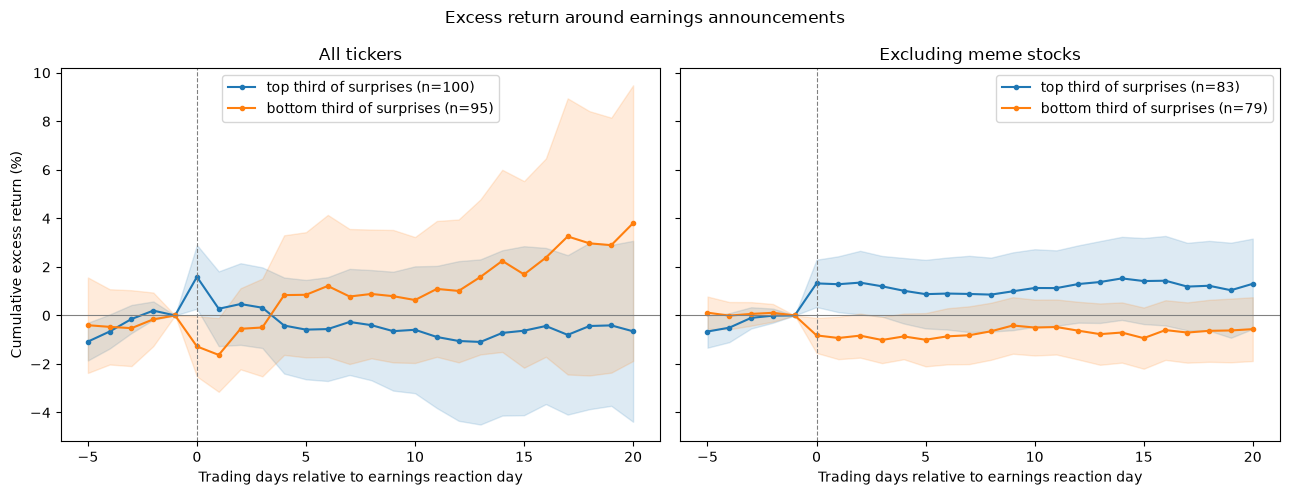

In [4]:
returns = pd.read_sql(
    "SELECT ticker, trade_date, excess_ret FROM marts.daily_features ORDER BY ticker, trade_date",
    engine, parse_dates=["trade_date"],
)
OFFSETS = list(range(-5, 21))
cols = [f"ret_{k}" for k in OFFSETS]

for k in OFFSETS:
    returns[f"ret_{k}"] = returns.groupby("ticker")["excess_ret"].shift(-k) * 100

paths = events.merge(returns, left_on=["ticker", "reaction_date"],
                     right_on=["ticker", "trade_date"], how="inner")

LABELS = {"high": "top third of surprises", "low": "bottom third of surprises"}
panels = {"All tickers": paths, "Excluding meme stocks": paths[paths["group"] != "Meme"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, data) in zip(axes, panels.items()):
    for bucket, label in LABELS.items():
        part = data[data["surprise_bucket"] == bucket][cols].dropna()
        cum = part.cumsum(axis=1)
        cum = cum.sub(cum["ret_-1"], axis=0)
        mean = cum.mean()
        se = cum.std() / np.sqrt(len(cum))

        line, = ax.plot(OFFSETS, mean.values, marker="o", markersize=3, label=f"{label} (n={len(cum)})")
        ax.fill_between(OFFSETS, (mean - 1.96 * se).values, (mean + 1.96 * se).values,
                        color=line.get_color(), alpha=0.15)

    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Trading days relative to earnings reaction day")
    ax.legend()

axes[0].set_ylabel("Cumulative excess return (%)")
fig.suptitle("Excess return around earnings announcements")
plt.tight_layout()

docs = Path("../docs")
docs.mkdir(exist_ok=True)
plt.savefig(docs / "earnings_event_study.png", dpi=150)
plt.show()

In [5]:
per_ticker = pd.DataFrame({
    ticker: {
        "n": len(g),
        "reaction_corr": g["surprise_rank"].corr(g["car_0_1_pct"], method="spearman"),
        "drift_corr": g["surprise_rank"].corr(g["car_drift_pct"], method="spearman"),
    }
    for ticker, g in events.groupby("ticker")
}).T

per_ticker.round(2).sort_values("reaction_corr", ascending=False)

,n,reaction_corr,drift_corr
O,27.0,0.53,-0.22
NVDA,27.0,0.35,0.04
MSFT,27.0,0.26,0.00
GS,28.0,0.22,0.05
DUK,27.0,0.07,-0.18
JPM,28.0,0.07,0.18
AAPL,27.0,0.03,-0.19
GME,24.0,0.02,0.06
BAC,28.0,0.02,0.30
NEE,27.0,-0.11,-0.16
